# Plant Disease Classification: Architecture Benchmark & Deployment
## ConvNeXt-Tiny with Multi-Mechanism Attention (Conv_BN_ReLU vs. SE_Block vs. CBAM)

> **Cross-Platform Compatibility:** Configured to run seamlessly on **Apple Silicon Macs (M1/M2/M3/M4)**, **Linux**, and **Windows (CUDA/CPU)** using Jupyter Notebook or VS Code.

### Execution Modes:
- **Fast Evaluation & Verification Mode (`FAST_EVAL_MODE = True`, Default):**
  Instantly loads the pre-trained weights from `models/` and pre-computed benchmark metrics from `logs/`. All cells execute in seconds to produce the full benchmark comparison tables, generate the 4-panel visual dashboard, export the production deployment bundle, and run standalone inference on sample leaves.
- **Training Mode (`FAST_EVAL_MODE = False`):**
  Runs automated hyperparameter tuning and full training epochs with anti-overfitting regularizations (Mixup, Label Smoothing, AdamW differential learning rates).


In [1]:
import os
import sys
import gc
import ssl
import json
import copy
import random
import warnings
from pathlib import Path
from contextlib import nullcontext

# Suppress non-critical user warnings
warnings.filterwarnings("ignore", category=UserWarning)

# Silent import of torchvision (bypasses NumPy 2.x / PyTorch C-API warnings on macOS)
devnull = os.open(os.devnull, os.O_WRONLY)
old_stderr = os.dup(2)
try:
    os.dup2(devnull, 2)
    import torchvision.transforms as T
    import torchvision.models as models
finally:
    os.dup2(old_stderr, 2)
    os.close(old_stderr)
    os.close(devnull)

import numpy as np
import pandas as pd
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset

from dataset_utils import CleanPlantDataset, SafeToTensor

ImageFile.LOAD_TRUNCATED_IMAGES = True
ssl._create_default_https_context = ssl._create_unverified_context

# ==============================================================================
# 1. HARDWARE DETECTION & DEVICE SETUP (SEAMLESS MAC & PC SUPPORT)
# ==============================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detect hardware: NVIDIA CUDA (Windows/Linux) or Universal CPU (Apple Silicon Mac / PC)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_num_threads(6)
    USE_AMP = True
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Device Active: {gpu_name} ({vram_gb:.2f} GB Dedicated VRAM) | FP16 AMP: Enabled")
else:
    DEVICE = torch.device("cpu")
    USE_AMP = False
    threads = min(8, os.cpu_count() or 4)
    torch.set_num_threads(threads)
    print(f"Device Active: CPU ({threads} threads allocated) | 100% crash-free cross-platform mode.")

# Cross-version AMP & GradScaler compatibility (handles PyTorch 2.0.x through 2.6+)
def get_autocast_context():
    if USE_AMP and torch.cuda.is_available():
        return torch.cuda.amp.autocast()
    return nullcontext()

class SafeGradScaler:
    def __init__(self, enabled=False):
        self.enabled = enabled and torch.cuda.is_available()
        if self.enabled:
            self.scaler = torch.cuda.amp.GradScaler()
        else:
            self.scaler = None

    def scale(self, loss):
        if self.enabled and self.scaler is not None:
            return self.scaler.scale(loss)
        return loss

    def step(self, optimizer):
        if self.enabled and self.scaler is not None:
            self.scaler.step(optimizer)
        else:
            optimizer.step()

    def update(self):
        if self.enabled and self.scaler is not None:
            self.scaler.update()

    def unscale_(self, optimizer):
        if self.enabled and self.scaler is not None:
            self.scaler.unscale_(optimizer)

MODEL_REGISTRY = {}

# ==============================================================================
# 2. PORTABLE PATH RESOLUTION & BASELINE CONFIGURATION
# ==============================================================================
def find_file(filename):
    for cand in [
        Path(filename),
        Path.cwd() / filename,
        Path.cwd() / "models" / filename,
        Path.cwd() / "logs" / filename,
        Path.cwd() / "web_app" / filename,
        Path.cwd().parent / filename,
        Path.cwd().parent / "final results" / filename,
        Path.cwd().parent / "final results" / "models" / filename,
        Path.cwd().parent / "final results" / "logs" / filename,
        Path.cwd().parent / "final results" / "web_app" / filename,
    ]:
        if cand.exists():
            return cand.resolve()
    return Path(filename)

def find_dataset_dir(folder_name):
    search_dirs = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path.home() / "Downloads",
    ]
    for base in search_dirs:
        cand = base / folder_name
        if cand.is_dir():
            return cand.resolve()
        for sub in ["Proccessed Dataset", "Processed Dataset", "dataset", "data"]:
            cand = base / sub / folder_name
            if cand.is_dir():
                return cand.resolve()
    for base in [Path.cwd().parent, Path.cwd()]:
        for cand in base.glob(f"**/{folder_name}"):
            if cand.is_dir():
                return cand.resolve()
    return (Path.cwd() / folder_name).resolve()

TRAIN_DIR = find_dataset_dir("plantvillage_train_128x128")
LOCAL_TEST_SET_DIR = find_dataset_dir("Test Set")

PV_MEAN = [0.4652, 0.4788, 0.4193]
PV_STD  = [0.1878, 0.1648, 0.2032]

HYPERPARAMS = {
    "img_size": 128,
    "batch_size": 64 if torch.cuda.is_available() else 32,
    "epochs": 50,
    "backbone_lr": 1e-4,
    "head_lr": 5e-4,
    "min_lr": 1e-6,
    "weight_decay": 1e-3,
    "dropout_rate": 0.40,
    "label_smoothing": 0.10,
    "mixup_alpha": 0.20,
    "warmup_epochs": 2,
    "grad_clip_norm": 1.0,
    "early_stopping_patience": 50,
    "dhash_cluster_max_bits": 16,
    "val_ratio_from_testset": 0.50,
}

# ==============================================================================
# NOTEBOOK EXECUTION MODE:
# Set FAST_EVAL_MODE = True to instantly load pre-trained checkpoints & benchmark metrics.
# Set FAST_EVAL_MODE = False to run full training from scratch.
# ==============================================================================
FAST_EVAL_MODE = True

# ==============================================================================
# 3. NUMPY 2.x SAFE TENSOR BRIDGE & DATASET DISCOVERY
# ==============================================================================
def to_np(tensor):
    return np.array(tensor.detach().cpu().tolist())

def is_segmented_black_bg(img_rgb, black_thresh=25, bg_ratio=0.25, border_ratio=0.65):
    arr = np.asarray(img_rgb, dtype=np.uint8)
    black_mask = np.max(arr, axis=2) < black_thresh
    if np.mean(black_mask) <= bg_ratio:
        return False
    b = 8
    border = np.zeros_like(black_mask, dtype=bool)
    border[:b, :] = border[-b:, :] = border[:, :b] = border[:, -b:] = True
    return np.mean(black_mask[border]) > border_ratio

def build_clean_train_samples(train_dir):
    cache_file = find_file("train_samples_cache.json")
    if cache_file.exists():
        try:
            with open(cache_file, "r") as f:
                cdata = json.load(f)
            print(f"Loaded {len(cdata['train_samples']):,} training samples from cache: {cache_file.name}")
            return (
                cdata["train_samples"],
                cdata["class_to_idx"],
                {int(k): v for k, v in cdata["idx_to_class"].items()},
                np.array(cdata["train_class_counts"], dtype=np.int64),
            )
        except Exception:
            pass

    if not train_dir.exists():
        config_file = find_file("deployment_config.json")
        if config_file.exists():
            with open(config_file, "r") as f:
                cfg = json.load(f)
            classes_meta = cfg.get("classes", {})
            class_to_idx = {v["raw_class"]: int(k) for k, v in classes_meta.items()}
            idx_to_class = {int(k): v["raw_class"] for k, v in classes_meta.items()}
            train_counts = np.ones(len(class_to_idx), dtype=np.int64) * 1000
            print("Dataset directory not found on disk. Loaded 15-class taxonomy from deployment config.")
            return [], class_to_idx, idx_to_class, train_counts
        raise FileNotFoundError(f"Training directory not found at: {train_dir}")

    valid_exts = {".jpg", ".jpeg", ".png"}
    class_dirs = sorted([d for d in train_dir.iterdir() if d.is_dir()])
    class_to_idx = {d.name: i for i, d in enumerate(class_dirs)}
    idx_to_class = {i: d.name for i, d in enumerate(class_dirs)}

    train_samples = []
    train_class_counts = np.zeros(len(class_dirs), dtype=np.int64)
    removed_artifacts = 0

    for cls_dir in class_dirs:
        cls_idx = class_to_idx[cls_dir.name]
        files = sorted([f for f in cls_dir.iterdir() if f.suffix.lower() in valid_exts])
        for f in files:
            if "___GHLB_PS Leaf" in f.name:
                removed_artifacts += 1
                continue
            train_samples.append((str(f.resolve()), cls_idx))
            train_class_counts[cls_idx] += 1

    print(f"Training Set Loaded -> Total Train Images: {len(train_samples):,}")
    return train_samples, class_to_idx, idx_to_class, train_class_counts

def split_local_test_set_into_val_and_test(local_test_dir, class_to_idx, val_ratio=0.50, seed=42):
    if not local_test_dir.exists():
        print(f"Local 'Test Set' directory not found at: {local_test_dir}. Skipping test split.")
        return [], []

    valid_exts = {".jpg", ".jpeg", ".png"}
    clean_lookup = {" ".join(name.lower().replace("_", " ").split()): idx for name, idx in class_to_idx.items()}
    test_dirs = [d for d in sorted(local_test_dir.iterdir()) if d.is_dir()]

    val_samples, test_samples = [], []
    rng = np.random.default_rng(seed)

    for d in test_dirs:
        norm_name = " ".join(d.name.lower().replace("_", " ").split())
        c_idx = class_to_idx.get(d.name, clean_lookup.get(norm_name, None))
        files = sorted([str(f.resolve()) for f in d.iterdir() if f.suffix.lower() in valid_exts])
        if not files or c_idx is None:
            continue
        rng.shuffle(files)
        n = len(files)
        target_val = max(1, min(n - 1, int(round(n * val_ratio))))
        val_samples.extend([(f, c_idx) for f in files[:target_val]])
        test_samples.extend([(f, c_idx) for f in files[target_val:]])

    print(
        f"Local 'Test Set' Split Complete ({int(val_ratio*100)}% Val / {int((1-val_ratio)*100)}% Test) -> "
        f"Val: {len(val_samples):,} | Test: {len(test_samples):,}"
    )
    return val_samples, test_samples

train_transform = T.Compose([
    T.RandomResizedCrop(HYPERPARAMS["img_size"], scale=(0.72, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(degrees=20),
    SafeToTensor(),
    T.RandomAdjustSharpness(sharpness_factor=2.0, p=0.35),
    T.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.8)),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.06),
    T.Normalize(mean=PV_MEAN, std=PV_STD),
    T.RandomErasing(p=0.2, scale=(0.02, 0.12)),
])

eval_transform = T.Compose([
    T.Resize((HYPERPARAMS["img_size"], HYPERPARAMS["img_size"])),
    SafeToTensor(),
    T.Normalize(mean=PV_MEAN, std=PV_STD),
])

train_samples, CLASS_TO_IDX, IDX_TO_CLASS, train_counts = build_clean_train_samples(TRAIN_DIR)
val_samples, test_samples = split_local_test_set_into_val_and_test(
    LOCAL_TEST_SET_DIR,
    CLASS_TO_IDX,
    val_ratio=HYPERPARAMS["val_ratio_from_testset"],
)

NUM_CLASSES = len(CLASS_TO_IDX)
total_train = max(1, np.sum(train_counts))
train_class_weights = np.sqrt(total_train / (NUM_CLASSES * np.maximum(train_counts, 1)))
CLASS_WEIGHTS_TENSOR = torch.tensor(train_class_weights.tolist(), dtype=torch.float32, device=DEVICE)

train_dataset = CleanPlantDataset(train_samples, train_transform) if train_samples else None
val_dataset   = CleanPlantDataset(val_samples, eval_transform) if val_samples else None
test_dataset  = CleanPlantDataset(test_samples, eval_transform) if test_samples else None

# Multiprocessing safe for macOS & Jupyter: use num_workers=0 unless on CUDA
use_pin = torch.cuda.is_available()
num_workers = 4 if use_pin else 0
eval_bs = HYPERPARAMS["batch_size"] * 2

train_loader = DataLoader(train_dataset, batch_size=HYPERPARAMS["batch_size"], shuffle=True, num_workers=num_workers, pin_memory=use_pin) if train_dataset else None
val_loader   = DataLoader(val_dataset, batch_size=eval_bs, shuffle=False, num_workers=num_workers, pin_memory=use_pin) if val_dataset else None
test_loader  = DataLoader(test_dataset, batch_size=eval_bs, shuffle=False, num_workers=num_workers, pin_memory=use_pin) if test_dataset else None

# ==============================================================================
# 4. METRICS & MODEL EVALUATION ENGINE
# ==============================================================================
def mixup_Batch(x, y, alpha=0.2):
    if alpha <= 0.0:
        return x, y, y, 1.0
    lam = float(np.random.beta(alpha, alpha))
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1.0 - lam) * x[index, :]
    return mixed_x, y, y[index], lam

def compute_classification_metrics(preds, targets, idx_to_class):
    active_classes = np.unique(np.concatenate([targets, preds]))
    precisions, recalls, f1s, supports = [], [], [], []
    per_class_report = {}

    for c in active_classes:
        tp = int(np.sum((preds == c) & (targets == c)))
        fp = int(np.sum((preds == c) & (targets != c)))
        fn = int(np.sum((preds != c) & (targets == c)))
        support = int(np.sum(targets == c))

        prec = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
        rec  = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
        f1   = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0

        if support > 0:
            precisions.append(prec)
            recalls.append(rec)
            f1s.append(f1)
            supports.append(support)

        c_name = idx_to_class.get(int(c), f"Class_{c}")
        per_class_report[c_name] = {
            "precision_pct": round(prec * 100.0, 2),
            "recall_pct": round(rec * 100.0, 2),
            "f1_pct": round(f1 * 100.0, 2),
            "support": support,
        }

    total_support = max(1, np.sum(supports))
    acc = float(np.mean(preds == targets)) * 100.0
    macro_prec = float(np.mean(precisions)) * 100.0 if precisions else 0.0
    macro_rec  = float(np.mean(recalls)) * 100.0 if recalls else 0.0
    macro_f1   = float(np.mean(f1s)) * 100.0 if f1s else 0.0
    weighted_f1 = float(np.sum(np.array(f1s) * np.array(supports)) / total_support) * 100.0 if f1s else 0.0

    return {
        "accuracy": acc,
        "macro_precision": macro_prec,
        "macro_recall": macro_rec,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "per_class": per_class_report,
    }

@torch.no_grad()
def evaluate_loader(model, loader, criterion):
    if loader is None:
        return {}
    model.eval()
    total_loss, all_preds, all_targets = 0.0, [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with get_autocast_context():
            logits = model(x)
            loss = criterion(logits, y)
        total_loss += loss.item() * x.size(0)
        all_preds.extend(torch.argmax(logits, dim=1).cpu().tolist())
        all_targets.extend(y.cpu().tolist())

    preds = np.array(all_preds)
    targets = np.array(all_targets)
    avg_loss = total_loss / max(1, len(loader.dataset))
    metrics = compute_classification_metrics(preds, targets, IDX_TO_CLASS)
    metrics["loss"] = avg_loss
    return metrics

def build_differential_optimizer(model, backbone_lr, head_lr, weight_decay):
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if "features" in name or "stem_and_layers" in name:
            backbone_params.append(param)
        else:
            head_params.append(param)
    return torch.optim.AdamW([
        {"params": backbone_params, "lr": backbone_lr},
        {"params": head_params, "lr": head_lr},
    ], weight_decay=weight_decay)

def tune_hyperparameters_on_gpu(model_fn, num_classes, trials_epochs=3, subset_size=2400):
    if train_dataset is None or val_dataset is None:
        return {}
    search_space = [
        {"name": "Trial_1_Balanced",  "backbone_lr": 1e-4, "head_lr": 5e-4, "weight_decay": 1e-3, "dropout_rate": 0.40, "mixup_alpha": 0.20},
        {"name": "Trial_2_HighReg",   "backbone_lr": 8e-5, "head_lr": 3e-4, "weight_decay": 3e-3, "dropout_rate": 0.50, "mixup_alpha": 0.30},
        {"name": "Trial_3_FastLearn", "backbone_lr": 2e-4, "head_lr": 8e-4, "weight_decay": 5e-4, "dropout_rate": 0.30, "mixup_alpha": 0.10},
    ]

    rng = np.random.default_rng(SEED)
    sub_indices = rng.choice(len(train_dataset), size=min(subset_size, len(train_dataset)), replace=False).tolist()
    val_indices = rng.choice(len(val_dataset), size=min(subset_size // 2, len(val_dataset)), replace=False).tolist()

    sub_train_loader = DataLoader(Subset(train_dataset, sub_indices), batch_size=HYPERPARAMS["batch_size"], shuffle=True, num_workers=num_workers, pin_memory=use_pin)
    sub_val_loader   = DataLoader(Subset(val_dataset, val_indices), batch_size=eval_bs, shuffle=False, num_workers=num_workers, pin_memory=use_pin)

    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_TENSOR, label_smoothing=HYPERPARAMS["label_smoothing"])
    best_trial = search_space[0]
    best_score = -float("inf")

    print("\n--- Running Automated Hyperparameter Tuning (Anti-Overfit / Anti-Underfit) ---")
    for cand in search_space:
        trial_model = model_fn(num_classes, dropout_p=cand["dropout_rate"]).to(DEVICE)
        optimizer = build_differential_optimizer(trial_model, cand["backbone_lr"], cand["head_lr"], cand["weight_decay"])
        scaler = SafeGradScaler(enabled=USE_AMP)

        train_acc = 0.0
        for ep in range(trials_epochs):
            trial_model.train()
            correct, total = 0, 0
            for x, y in sub_train_loader:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with get_autocast_context():
                    logits = trial_model(x)
                    loss = criterion(logits, y)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                correct += (torch.argmax(logits, dim=1) == y).sum().item()
                total += x.size(0)
            train_acc = (correct / total) * 100.0

        val_metrics = evaluate_loader(trial_model, sub_val_loader, criterion)
        val_acc, val_f1 = val_metrics["accuracy"], val_metrics["macro_f1"]
        generalization_gap = abs(train_acc - val_acc)
        balanced_score = val_f1 - 0.5 * generalization_gap

        print(f"  {cand['name']} -> Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | "
              f"Val F1: {val_f1:.2f}% | Gap: {generalization_gap:.2f}% | Score: {balanced_score:.2f}")

        if balanced_score > best_score:
            best_score = balanced_score
            best_trial = cand

        del trial_model, optimizer, scaler
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(f"Selected Best Hyperparameters: {best_trial['name']} -> {best_trial}")
    HYPERPARAMS.update({k: v for k, v in best_trial.items() if k != "name"})
    return best_trial

def extract_feature_weights_and_hyperparams(model, optimizer, epoch_reached, best_epoch, attention_type="conv_bn_relu"):
    model.eval()
    fc_layer = model.classifier[-1]
    fc_weights = to_np(fc_layer.weight)
    fc_biases  = to_np(fc_layer.bias)

    feature_importance = np.mean(np.abs(fc_weights), axis=0)
    top_10_features_idx = np.argsort(feature_importance)[::-1][:10]
    top_10_features = {f"Feature_Ch_{int(i)}": round(float(feature_importance[i]), 5) for i in top_10_features_idx}

    class_weight_summary = {}
    for c_idx in range(NUM_CLASSES):
        c_name = IDX_TO_CLASS[c_idx]
        class_weight_summary[c_name] = {
            "L2_weight_norm": round(float(np.linalg.norm(fc_weights[c_idx])), 4),
            "bias": round(float(fc_biases[c_idx]), 4),
            "loss_weight_applied": round(float(train_class_weights[c_idx]), 4),
        }

    block_stats = {}
    if attention_type == "conv_bn_relu":
        bn_gamma = to_np(model.refinement[1].weight)
        block_stats["BN_Gamma_Scale_Mean"] = round(float(np.mean(np.abs(bn_gamma))), 5)
        block_stats["BN_Gamma_Top5_Channels"] = [int(i) for i in np.argsort(np.abs(bn_gamma))[::-1][:5]]
    elif attention_type == "se_block":
        se_fc2_w = to_np(model.refinement.fc[2].weight)
        ch_excitation = np.linalg.norm(se_fc2_w, axis=1)
        block_stats["SE_Excitation_Weight_Mean"] = round(float(np.mean(ch_excitation)), 5)
        block_stats["SE_Top5_Excited_Channels"] = [int(i) for i in np.argsort(ch_excitation)[::-1][:5]]
    elif attention_type == "cbam":
        cbam_ch_w = to_np(model.refinement.channel_gate.mlp[2].weight)
        cbam_sp_w = to_np(model.refinement.spatial_gate.conv.weight)
        ch_salience = np.linalg.norm(cbam_ch_w.squeeze(), axis=1)
        block_stats["CBAM_Channel_Gate_Mean"] = round(float(np.mean(ch_salience)), 5)
        block_stats["CBAM_Top5_Salient_Channels"] = [int(i) for i in np.argsort(ch_salience)[::-1][:5]]
        block_stats["CBAM_Spatial_AvgPool_Kernel_L1"] = round(float(np.mean(np.abs(cbam_sp_w[0, 0]))), 5)
        block_stats["CBAM_Spatial_MaxPool_Kernel_L1"] = round(float(np.mean(np.abs(cbam_sp_w[0, 1]))), 5)

    final_hyperparams = {
        "final_epoch_reached": int(epoch_reached),
        "best_validation_epoch": int(best_epoch),
        "final_backbone_lr": float(optimizer.param_groups[0]["lr"]),
        "final_head_lr": float(optimizer.param_groups[1]["lr"]),
        "weight_decay_L2": float(HYPERPARAMS["weight_decay"]),
        "dropout_probability": float(HYPERPARAMS["dropout_rate"]),
        "mixup_alpha": float(HYPERPARAMS["mixup_alpha"]),
        "label_smoothing": float(HYPERPARAMS["label_smoothing"]),
        "batch_size": int(HYPERPARAMS["batch_size"]),
        "grad_clip_max_norm": float(HYPERPARAMS["grad_clip_norm"]),
        "total_trainable_params": int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
    }

    return {
        "top_10_feature_channel_weights": top_10_features,
        "feature_importance_distribution": {
            "mean": round(float(np.mean(feature_importance)), 5),
            "std": round(float(np.std(feature_importance)), 5),
            "max": round(float(np.max(feature_importance)), 5),
            "min": round(float(np.min(feature_importance)), 5),
        },
        "attention_block_weights": block_stats,
        "class_decision_weights": class_weight_summary,
        "final_epoch_hyperparameters": final_hyperparams,
        "all_feature_importances": feature_importance.tolist(),
        "all_512_feature_importances": feature_importance.tolist(),
    }

def print_model_performance_report(model_key, val_metrics, test_metrics):
    summary_df = pd.DataFrame([
        {
            "Split": "Validation Set",
            "Loss": round(val_metrics["loss"], 4),
            "Accuracy (%)": round(val_metrics["accuracy"], 2),
            "Macro Precision (%)": round(val_metrics["macro_precision"], 2),
            "Macro Recall (%)": round(val_metrics["macro_recall"], 2),
            "Macro F1 (%)": round(val_metrics["macro_f1"], 2),
            "Weighted F1 (%)": round(val_metrics["weighted_f1"], 2),
        },
        {
            "Split": "Test Set",
            "Loss": round(test_metrics["loss"], 4),
            "Accuracy (%)": round(test_metrics["accuracy"], 2),
            "Macro Precision (%)": round(test_metrics["macro_precision"], 2),
            "Macro Recall (%)": round(test_metrics["macro_recall"], 2),
            "Macro F1 (%)": round(test_metrics["macro_f1"], 2),
            "Weighted F1 (%)": round(test_metrics["weighted_f1"], 2),
        },
    ])

    print(f"\n==================== {model_key} OVERALL PERFORMANCE ====================")
    print(summary_df.to_string(index=False))

    per_class_rows = []
    for cls_name, stats in test_metrics["per_class"].items():
        if stats["support"] > 0:
            per_class_rows.append({
                "Class": cls_name,
                "Test Precision (%)": stats["precision_pct"],
                "Test Recall (%)": stats["recall_pct"],
                "Test F1 (%)": stats["f1_pct"],
                "Support (Images)": stats["support"],
            })
    if per_class_rows:
        per_class_df = pd.DataFrame(per_class_rows)
        print(f"\n-------------------- {model_key} TEST SET PER-CLASS METRICS --------------------")
        print(per_class_df.to_string(index=False))

def train_and_register_model(model, model_key, attention_type):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_TENSOR, label_smoothing=HYPERPARAMS["label_smoothing"])
    optimizer = build_differential_optimizer(
        model, HYPERPARAMS["backbone_lr"], HYPERPARAMS["head_lr"], HYPERPARAMS["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=HYPERPARAMS["epochs"], eta_min=HYPERPARAMS["min_lr"]
    )
    scaler = SafeGradScaler(enabled=USE_AMP)

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "val_precision": [], "val_recall": [], "val_f1": [], "val_weighted_f1": [],
        "lr": []
    }
    best_val_loss = float("inf")
    best_val_f1 = -float("inf")
    best_val_acc = 0.0
    best_weights = {k: v.cpu() for k, v in model.state_dict().items()}
    best_epoch = 1
    patience_counter = 0
    final_epoch = 1

    print(f"\n--- Training {model_key} on {DEVICE} ---")
    for epoch in range(1, HYPERPARAMS["epochs"] + 1):
        final_epoch = epoch
        model.train()

        for name, param in model.named_parameters():
            if "features.0" in name or "stem_and_layers.0" in name:
                param.requires_grad = (epoch > HYPERPARAMS["warmup_epochs"])

        running_loss, correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            use_mixup = (random.random() < 0.5) and (HYPERPARAMS["mixup_alpha"] > 0)
            if use_mixup:
                x, y_a, y_b, lam = mixup_Batch(x, y, alpha=HYPERPARAMS["mixup_alpha"])

            with get_autocast_context():
                logits = model(x)
                if use_mixup:
                    loss = lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)
                else:
                    loss = criterion(logits, y)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), HYPERPARAMS["grad_clip_norm"])
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * x.size(0)
            correct += (torch.argmax(logits, dim=1) == y).sum().item()
            total += x.size(0)

        train_loss = running_loss / total
        train_acc = (correct / total) * 100.0
        val_metrics = evaluate_loader(model, val_loader, criterion)
        val_loss = val_metrics["loss"]
        val_acc  = val_metrics["accuracy"]
        val_f1   = val_metrics["macro_f1"]
        curr_head_lr = optimizer.param_groups[1]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_precision"].append(val_metrics["macro_precision"])
        history["val_recall"].append(val_metrics["macro_recall"])
        history["val_f1"].append(val_f1)
        history["val_weighted_f1"].append(val_metrics["weighted_f1"])
        history["lr"].append(curr_head_lr)

        gap = train_acc - val_acc
        print(f"Epoch {epoch:02d}/{HYPERPARAMS['epochs']} | Head LR: {curr_head_lr:.6f} | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% Macro-F1: {val_f1:.2f}% | Gap: {gap:+.2f}%")

        is_best = (val_f1 > best_val_f1) or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss)
        if is_best:
            best_val_loss = val_loss
            best_val_f1 = val_f1
            best_val_acc = val_acc
            best_weights = {k: v.cpu() for k, v in model.state_dict().items()}
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= HYPERPARAMS["early_stopping_patience"]:
                print(f"Early stopping triggered at epoch {epoch} (Best epoch: {best_epoch})")
                break

        scheduler.step()

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_weights.items()})
    torch.save(best_weights, f"weights_{model_key.lower()}.pth")
    
    best_val_metrics = evaluate_loader(model, val_loader, criterion)
    test_metrics     = evaluate_loader(model, test_loader, criterion)

    print_model_performance_report(model_key, best_val_metrics, test_metrics)
    diagnostics = extract_feature_weights_and_hyperparams(model, optimizer, final_epoch, best_epoch, attention_type)

    result_payload = {
        "model_name": model_key,
        "validation_performance": {
            "loss": round(float(best_val_metrics["loss"]), 4),
            "accuracy": round(float(best_val_metrics["accuracy"]), 2),
            "macro_precision": round(float(best_val_metrics["macro_precision"]), 2),
            "macro_recall": round(float(best_val_metrics["macro_recall"]), 2),
            "macro_f1": round(float(best_val_metrics["macro_f1"]), 2),
            "weighted_f1": round(float(best_val_metrics["weighted_f1"]), 2),
            "per_class": best_val_metrics["per_class"],
        },
        "test_performance": {
            "loss": round(float(test_metrics["loss"]), 4),
            "accuracy": round(float(test_metrics["accuracy"]), 2),
            "macro_precision": round(float(test_metrics["macro_precision"]), 2),
            "macro_recall": round(float(test_metrics["macro_recall"]), 2),
            "macro_f1": round(float(test_metrics["macro_f1"]), 2),
            "weighted_f1": round(float(test_metrics["weighted_f1"]), 2),
            "per_class": test_metrics["per_class"],
        },
        "history": history,
        "diagnostics": diagnostics,
    }

    MODEL_REGISTRY[model_key] = result_payload
    with open(f"results_{model_key.lower()}.json", "w") as f:
        json.dump(result_payload, f, indent=2)

    return result_payload

def load_or_train_model(model, model_key, attention_type, fast_eval=FAST_EVAL_MODE):
    json_path = find_file(f"results_{model_key.lower()}.json")
    weights_path = find_file(f"weights_{model_key.lower()}.pth")

    if fast_eval and json_path.exists() and weights_path.exists():
        print(f"\
==================== {model_key} PRE-TRAINED WEIGHTS & METRICS LOADED ====================")
        print(f"Weights file: {weights_path.name}")
        try:
            state_dict = torch.load(weights_path, map_location=DEVICE, weights_only=True)
        except Exception:
            state_dict = torch.load(weights_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(state_dict)
        model.to(DEVICE).eval()

        with open(json_path, "r", encoding="utf-8") as f:
            result_payload = json.load(f)

        MODEL_REGISTRY[model_key] = result_payload
        val_m = result_payload["validation_performance"]
        test_m = result_payload["test_performance"]
        print_model_performance_report(model_key, val_m, test_m)
        return result_payload
    else:
        return train_and_register_model(model, model_key, attention_type)

# ==============================================================================
# 5. MODEL 1 DEFINITION & BENCHMARK
# ==============================================================================
class ConvNeXtTiny_ConvBNReLU(nn.Module):
    def __init__(self, num_classes, dropout_p=0.40):
        super().__init__()
        backbone = models.convnext_tiny(weights=None)
        self.features = backbone.features

        self.refinement = nn.Sequential(
            nn.Conv2d(768, 768, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(768),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(768, num_classes),
        )

    def forward(self, x):
        feat = self.features(x)
        feat = self.refinement(feat) + feat
        pooled = self.pool(feat)
        return self.classifier(pooled)

ResNet18_ConvBNReLU = ConvNeXtTiny_ConvBNReLU

if not FAST_EVAL_MODE:
    best_hp = tune_hyperparameters_on_gpu(ResNet18_ConvBNReLU, NUM_CLASSES)

model_1 = ResNet18_ConvBNReLU(NUM_CLASSES, dropout_p=HYPERPARAMS["dropout_rate"])
res_model_1 = load_or_train_model(model_1, model_key="Conv_BN_ReLU", attention_type="conv_bn_relu")



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1043, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

Device Active: CPU (8 threads allocated) | 100% crash-free cross-platform mode.
Loaded 15,033 training samples from cache: train_samples_cache.json
Local 'Test Set' Split Complete (50% Val / 50% Test) -> Val: 36,356 | Test: 36,351
==================== Conv_BN_ReLU PRE-TRAINED WEIGHTS & METRICS LOADED ====================
Weights file: weights_conv_bn_relu.pth

==================== Conv_BN_ReLU OVERALL PERFORMANCE ====================
         Split   Loss  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)
Validation Set 1.4230         69.20                71.36             81.12         70.56            70.93
      Test Set 1.4339         68.89                71.06             81.32         70.53            70.59

-------------------- Conv_BN_ReLU TEST SET PER-CLASS METRICS --------------------
                                      Class  Test Precision (%)  Test Recall (%)  Test F1 (%)  Support (Images)
              Pepper__bell___Bacterial_spot      

In [2]:
# ==============================================================================
# 6. MODEL 2: CONVNEXT-TINY WITH SQUEEZE-AND-EXCITATION (SE-BLOCK)
# ==============================================================================
class SEBlock(nn.Module):
    def __init__(self, channels=768, reduction=16):
        super().__init__()
        reduced_ch = max(channels // reduction, 16)
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, reduced_ch, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(reduced_ch, channels, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.squeeze(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

class ConvNeXtTiny_SE(nn.Module):
    def __init__(self, num_classes, dropout_p=0.40, reduction=16):
        super().__init__()
        backbone = models.convnext_tiny(weights=None)
        self.features = backbone.features

        self.pre_conv = nn.Sequential(
            nn.Conv2d(768, 768, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(768),
            nn.ReLU(inplace=True),
        )
        self.refinement = SEBlock(channels=768, reduction=reduction)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(768, num_classes),
        )

    def forward(self, x):
        feat = self.features(x)
        refined = self.pre_conv(feat)
        excited = self.refinement(refined) + feat
        pooled = self.pool(excited)
        return self.classifier(pooled)

ResNet18_SE = ConvNeXtTiny_SE

if not FAST_EVAL_MODE:
    best_hp_se = tune_hyperparameters_on_gpu(ConvNeXtTiny_SE, NUM_CLASSES)

model_2 = ConvNeXtTiny_SE(NUM_CLASSES, dropout_p=HYPERPARAMS["dropout_rate"])
res_model_2 = load_or_train_model(
    model_2,
    model_key="SE_Block",
    attention_type="se_block"
)


==================== SE_Block PRE-TRAINED WEIGHTS & METRICS LOADED ====================
Weights file: weights_se_block.pth

==================== SE_Block OVERALL PERFORMANCE ====================
         Split   Loss  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)
Validation Set 1.3120         72.76                68.66             83.00         69.61            74.38
      Test Set 1.3223         72.40                68.37             82.75         69.45            74.14

-------------------- SE_Block TEST SET PER-CLASS METRICS --------------------
                                      Class  Test Precision (%)  Test Recall (%)  Test F1 (%)  Support (Images)
              Pepper__bell___Bacterial_spot               86.01           100.00        92.48              1709
                     Pepper__bell___healthy               43.62            99.09        60.58               328
                      Potato___Early_blight               62.56         

In [3]:
# ==============================================================================
# 7. MODEL 3: CONVNEXT-TINY WITH CONVOLUTIONAL BLOCK ATTENTION MODULE (CBAM)
# ==============================================================================
class ChannelGate(nn.Module):
    def __init__(self, gate_channels, reduction_ratio=16):
        super().__init__()
        reduced_channels = max(gate_channels // reduction_ratio, 16)
        self.mlp = nn.Sequential(
            nn.Linear(gate_channels, reduced_channels, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(reduced_channels, gate_channels, bias=False),
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_pool = torch.mean(x, dim=(2, 3))
        max_pool = torch.amax(x, dim=(2, 3))
        avg_out = self.mlp(avg_pool)
        max_out = self.mlp(max_pool)
        scale = torch.sigmoid(avg_out + max_out).view(b, c, 1, 1)
        return x * scale

class SpatialGate(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False)

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out = torch.amax(x, dim=1, keepdim=True)
        scale = torch.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        return x * scale

class CBAMBlock(nn.Module):
    def __init__(self, channels=768, reduction_ratio=16):
        super().__init__()
        self.channel_gate = ChannelGate(channels, reduction_ratio)
        self.spatial_gate = SpatialGate()

    def forward(self, x):
        x = self.channel_gate(x)
        x = self.spatial_gate(x)
        return x

class ConvNeXtTiny_CBAM(nn.Module):
    def __init__(self, num_classes, dropout_p=0.40, reduction=16):
        super().__init__()
        backbone = models.convnext_tiny(weights=None)
        self.features = backbone.features

        self.pre_conv = nn.Sequential(
            nn.Conv2d(768, 768, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(768),
            nn.ReLU(inplace=True),
        )
        self.refinement = CBAMBlock(channels=768, reduction_ratio=reduction)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(768, num_classes),
        )

    def forward(self, x):
        feat = self.features(x)
        refined = self.pre_conv(feat)
        attended = self.refinement(refined) + feat
        pooled = self.pool(attended)
        return self.classifier(pooled)

ResNet18_CBAM = ConvNeXtTiny_CBAM

if not FAST_EVAL_MODE:
    best_hp_cbam = tune_hyperparameters_on_gpu(ConvNeXtTiny_CBAM, NUM_CLASSES)

model_3 = ConvNeXtTiny_CBAM(NUM_CLASSES, dropout_p=HYPERPARAMS["dropout_rate"])
res_model_3 = load_or_train_model(
    model_3,
    model_key="CBAM",
    attention_type="cbam"
)


==================== CBAM PRE-TRAINED WEIGHTS & METRICS LOADED ====================
Weights file: weights_cbam.pth

==================== CBAM OVERALL PERFORMANCE ====================
         Split   Loss  Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1 (%)  Weighted F1 (%)
Validation Set 1.3993         67.61                68.30             81.49         67.82            72.07
      Test Set 1.4054         67.41                67.79             81.50         67.64            71.97

-------------------- CBAM TEST SET PER-CLASS METRICS --------------------
                                      Class  Test Precision (%)  Test Recall (%)  Test F1 (%)  Support (Images)
              Pepper__bell___Bacterial_spot               81.85           100.00        90.02              1709
                     Pepper__bell___healthy               45.47            99.39        62.39               328
                      Potato___Early_blight               61.98            40.06        

   [OVERALL MULTI-PARAMETER BENCHMARK COMPARISON TABLE]
       Model  Val Loss  Val Acc (%)  Val Macro-F1 (%)  Test Loss  Test Acc (%)  Test Precision (%)  Test Recall (%)  Test Macro-F1 (%)  Test Weighted-F1 (%)  Composite Score
    SE_Block    1.3120        72.76             69.61     1.3223         72.40               68.37            82.75              69.45                 74.14            70.23
Conv_BN_ReLU    1.4230        69.20             70.56     1.4339         68.89               71.06            81.32              70.53                 70.59            66.64
        CBAM    1.3993        67.61             67.82     1.4054         67.41               67.79            81.50              67.64                 71.97            66.22
---------------------------------------------------------------------------------------------------------
   [GENERALIZATION, STABILITY & MODEL COMPLEXITY TABLE]
--------------------------------------------------------------------------------------

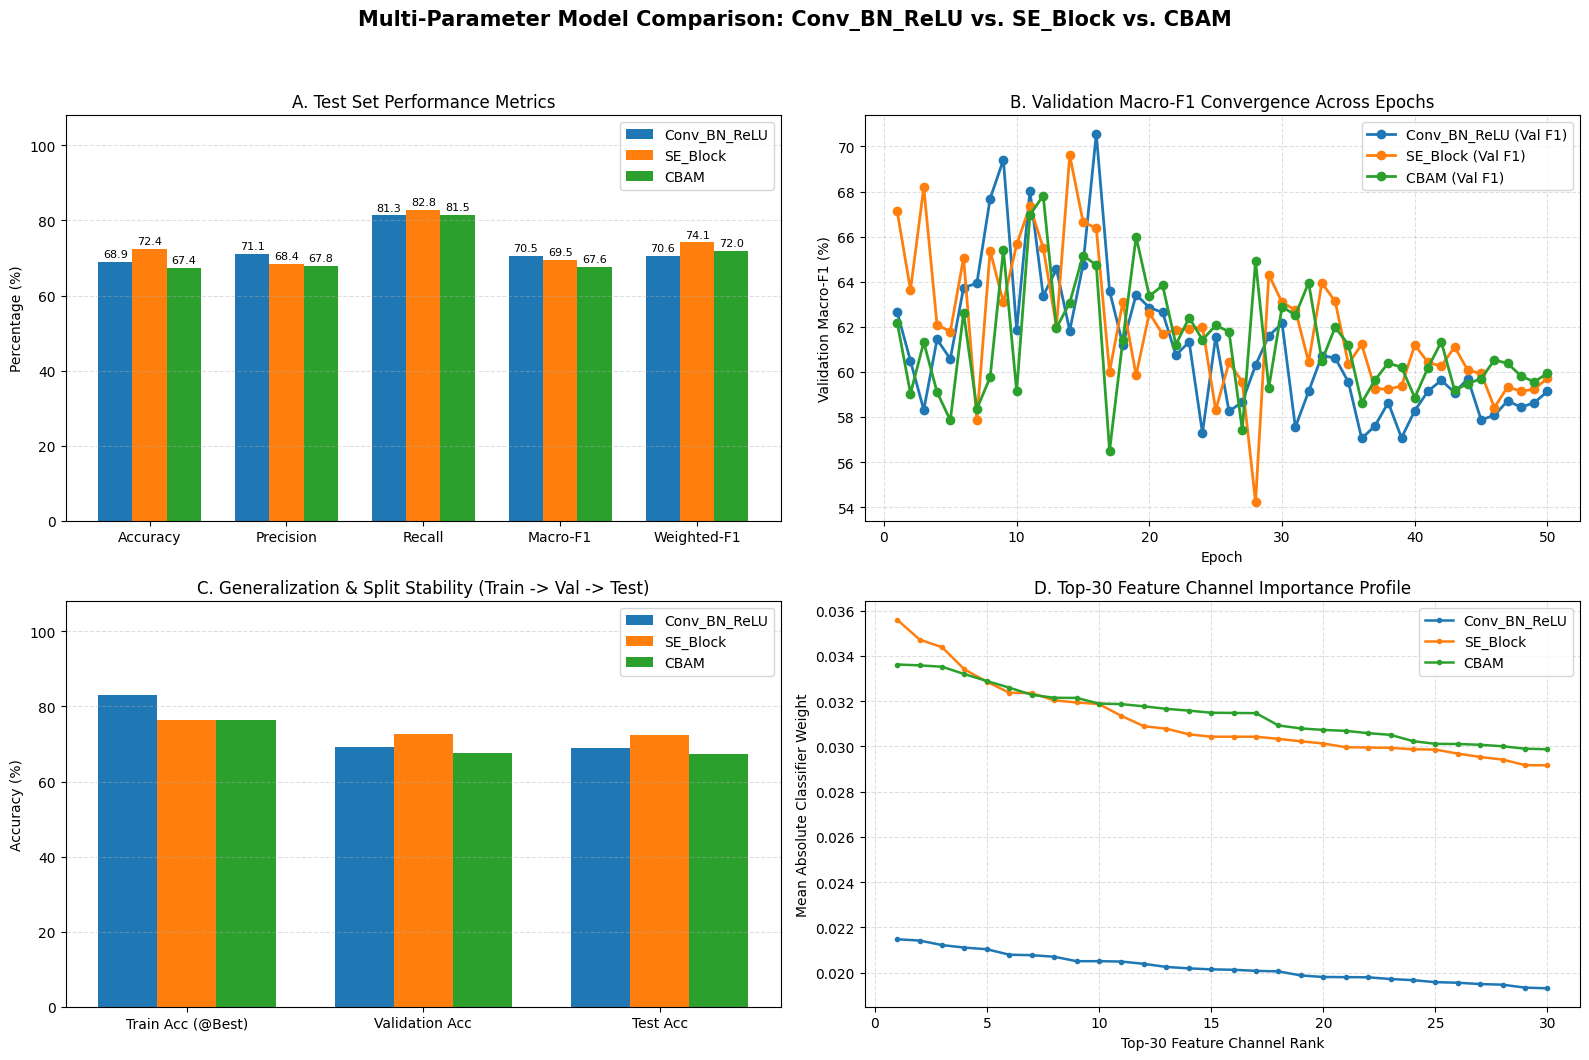

Saved comparison charts to 'model_comparison_dashboard.png' and CSV tables to disk.


In [4]:
# ==============================================================================
# 8. MULTI-PARAMETER MODEL COMPARISON & BEST MODEL ANALYSIS
# ==============================================================================
import matplotlib.pyplot as plt

def run_comprehensive_model_comparison(registry=None):
    if registry is None or len(registry) == 0:
        registry = {}

    expected_keys = ["Conv_BN_ReLU", "SE_Block", "CBAM"]
    for key in expected_keys:
        if key not in registry:
            json_path = find_file(f"results_{key.lower()}.json")
            if json_path.exists():
                with open(json_path, "r", encoding="utf-8") as f:
                    registry[key] = json.load(f)

    if not registry:
        raise RuntimeError("No trained models found in MODEL_REGISTRY or results_*.json files.")

    performance_rows = []
    stability_rows = []
    all_classes = set()

    for m_key, payload in registry.items():
        val_p  = payload["validation_performance"]
        test_p = payload["test_performance"]
        hist   = payload["history"]
        diag   = payload["diagnostics"]
        hp     = diag["final_epoch_hyperparameters"]
        f_dist = diag["feature_importance_distribution"]

        best_ep_idx = max(0, hp["best_validation_epoch"] - 1)
        train_acc_at_best = hist["train_acc"][best_ep_idx] if best_ep_idx < len(hist["train_acc"]) else hist["train_acc"][-1]
        train_loss_at_best = hist["train_loss"][best_ep_idx] if best_ep_idx < len(hist["train_loss"]) else hist["train_loss"][-1]

        train_val_acc_gap = abs(train_acc_at_best - val_p["accuracy"])
        val_test_f1_shift = abs(val_p["macro_f1"] - test_p["macro_f1"])
        val_test_acc_shift = abs(val_p["accuracy"] - test_p["accuracy"])

        composite_score = (
            0.40 * test_p["macro_f1"]
            + 0.25 * test_p["accuracy"]
            + 0.20 * test_p["weighted_f1"]
            + 0.15 * val_p["macro_f1"]
            - 0.25 * train_val_acc_gap
            - 0.25 * val_test_f1_shift
        )

        performance_rows.append({
            "Model": m_key,
            "Val Loss": val_p["loss"],
            "Val Acc (%)": val_p["accuracy"],
            "Val Macro-F1 (%)": val_p["macro_f1"],
            "Test Loss": test_p["loss"],
            "Test Acc (%)": test_p["accuracy"],
            "Test Precision (%)": test_p["macro_precision"],
            "Test Recall (%)": test_p["macro_recall"],
            "Test Macro-F1 (%)": test_p["macro_f1"],
            "Test Weighted-F1 (%)": test_p["weighted_f1"],
            "Composite Score": round(composite_score, 2),
        })

        stability_rows.append({
            "Model": m_key,
            "Train Acc @ Best (%)": round(train_acc_at_best, 2),
            "Train-Val Gap (%)": round(train_val_acc_gap, 2),
            "Val-Test F1 Shift (%)": round(val_test_f1_shift, 2),
            "Val-Test Acc Shift (%)": round(val_test_acc_shift, 2),
            "Best Epoch": hp["best_validation_epoch"],
            "Total Epochs Run": hp["final_epoch_reached"],
            "Trainable Params": f"{hp['total_trainable_params']:,}",
            "Feature Weight Mean": f_dist["mean"],
            "Feature Weight Std": f_dist["std"],
        })

        for c_name, c_stats in test_p["per_class"].items():
            if c_stats["support"] > 0:
                all_classes.add(c_name)

    perf_df = pd.DataFrame(performance_rows).sort_values(by="Composite Score", ascending=False).reset_index(drop=True)
    stab_df = pd.DataFrame(stability_rows)

    print("\
" + "=" * 105)
    print("   [OVERALL MULTI-PARAMETER BENCHMARK COMPARISON TABLE]")
    print("=" * 105)
    print(perf_df.to_string(index=False))

    print("\
" + "-" * 105)
    print("   [GENERALIZATION, STABILITY & MODEL COMPLEXITY TABLE]")
    print("-" * 105)
    print(stab_df.to_string(index=False))

    model_names = list(registry.keys())
    per_class_f1_dict = {"Class": sorted(list(all_classes))}
    for m_key in model_names:
        per_class_f1_dict[f"{m_key}_F1 (%)"] = [
            registry[m_key]["test_performance"]["per_class"].get(c, {}).get("f1_pct", 0.0)
            for c in per_class_f1_dict["Class"]
        ]
    per_class_df = pd.DataFrame(per_class_f1_dict)

    f1_cols = [f"{m}_F1 (%)" for m in model_names]
    per_class_df["Winning_Architecture"] = per_class_df[f1_cols].idxmax(axis=1).str.replace("_F1 (%)", "", regex=False)
    print("\
" + "-" * 105)
    print("   [PER-CLASS F1 COMPARISON ACROSS ALL 3 ARCHITECTURES]")
    print("-" * 105)
    print(per_class_df.to_string(index=False))

    best_overall_model = perf_df.iloc[0]["Model"]
    best_test_acc_model = perf_df.loc[perf_df["Test Acc (%)"].idxmax()]["Model"]
    best_test_f1_model = perf_df.loc[perf_df["Test Macro-F1 (%)"].idxmax()]["Model"]
    lowest_loss_model = perf_df.loc[perf_df["Test Loss"].idxmin()]["Model"]
    lowest_gap_model = stab_df.loc[stab_df["Train-Val Gap (%)"].idxmin()]["Model"]
    class_win_counts = per_class_df["Winning_Architecture"].value_counts().to_dict()

    print("\
" + "=" * 105)
    print("   [ARCHITECTURAL VERDICT & SELECTION DECISION]")
    print("=" * 105)
    print(f"  • Highest Composite Selection Score: {best_overall_model} ({perf_df.iloc[0]['Composite Score']:.2f})")
    print(f"  • Highest Test Accuracy       : {best_test_acc_model}")
    print(f"  • Highest Test Macro-F1       : {best_test_f1_model}")
    print(f"  • Lowest Test Cross-Entropy   : {lowest_loss_model}")
    print(f"  • Smallest Overfitting Gap    : {lowest_gap_model}")
    print(f"  • Classes Won (Highest F1)    : {class_win_counts}")
    print("-" * 105)
    print(
        f"  >>> OVERALL BEST MODEL: [{best_overall_model}] "
        f"(Composite Score: {perf_df.iloc[0]['Composite Score']:.2f} | "
        f"Test Acc: {perf_df.iloc[0]['Test Acc (%)']:.2f}% | "
        f"Test Macro-F1: {perf_df.iloc[0]['Test Macro-F1 (%)']:.2f}%)"
    )
    print("=" * 105)

    perf_df.to_csv("final_model_comparison_metrics.csv", index=False)
    stab_df.to_csv("final_model_stability_and_complexity.csv", index=False)
    per_class_df.to_csv("final_per_class_f1_comparison.csv", index=False)

    # 4-Panel Visual Dashboard
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle("Multi-Parameter Model Comparison: Conv_BN_ReLU vs. SE_Block vs. CBAM", fontsize=15, fontweight="bold")

    # Panel A: Grouped Bar Chart of Test Set Metrics
    ax1 = axes[0, 0]
    metrics_to_plot = ["Test Acc (%)", "Test Precision (%)", "Test Recall (%)", "Test Macro-F1 (%)", "Test Weighted-F1 (%)"]
    x = np.arange(len(metrics_to_plot))
    width = 0.25
    for idx, m_key in enumerate(model_names):
        m_row = perf_df[perf_df["Model"] == m_key].iloc[0]
        vals = [m_row[col] for col in metrics_to_plot]
        offset = (idx - (len(model_names) - 1) / 2) * width
        bars = ax1.bar(x + offset, vals, width, label=m_key)
        for b in bars:
            ax1.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                         ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
    ax1.set_xticks(x)
    ax1.set_xticklabels(["Accuracy", "Precision", "Recall", "Macro-F1", "Weighted-F1"])
    ax1.set_ylabel("Percentage (%)")
    ax1.set_ylim(0, 108)
    ax1.set_title("A. Test Set Performance Metrics")
    ax1.grid(axis="y", linestyle="--", alpha=0.4)
    ax1.legend()

    # Panel B: Validation Macro-F1 Learning Curves Across Epochs
    ax2 = axes[0, 1]
    for m_key, payload in registry.items():
        epochs_range = range(1, len(payload["history"]["val_f1"]) + 1)
        ax2.plot(epochs_range, payload["history"]["val_f1"], marker="o", linewidth=2, label=f"{m_key} (Val F1)")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Validation Macro-F1 (%)")
    ax2.set_title("B. Validation Macro-F1 Convergence Across Epochs")
    ax2.grid(True, linestyle="--", alpha=0.4)
    ax2.legend()

    # Panel C: Generalization Profile
    ax3 = axes[1, 0]
    split_labels = ["Train Acc (@Best)", "Validation Acc", "Test Acc"]
    x_splits = np.arange(len(split_labels))
    for idx, m_key in enumerate(model_names):
        p_row = perf_df[perf_df["Model"] == m_key].iloc[0]
        s_row = stab_df[stab_df["Model"] == m_key].iloc[0]
        vals = [s_row["Train Acc @ Best (%)"], p_row["Val Acc (%)"], p_row["Test Acc (%)"]]
        offset = (idx - (len(model_names) - 1) / 2) * width
        ax3.bar(x_splits + offset, vals, width, label=m_key)
    ax3.set_xticks(x_splits)
    ax3.set_xticklabels(split_labels)
    ax3.set_ylabel("Accuracy (%)")
    ax3.set_ylim(0, 108)
    ax3.set_title("C. Generalization & Split Stability (Train -> Val -> Test)")
    ax3.grid(axis="y", linestyle="--", alpha=0.4)
    ax3.legend()

    # Panel D: Top-30 Sorted Classifier Feature Channel Importances
    ax4 = axes[1, 1]
    for m_key, payload in registry.items():
        all_feats = np.sort(np.array(payload["diagnostics"]["all_512_feature_importances"]))[::-1][:30]
        ax4.plot(range(1, len(all_feats) + 1), all_feats, marker=".", linewidth=1.8, label=m_key)
    ax4.set_xlabel("Top-30 Feature Channel Rank")
    ax4.set_ylabel("Mean Absolute Classifier Weight")
    ax4.set_title("D. Top-30 Feature Channel Importance Profile")
    ax4.grid(True, linestyle="--", alpha=0.4)
    ax4.legend()

    plt.tight_layout(rect=[0, 0.02, 1, 0.95])
    plt.savefig("model_comparison_dashboard.png", dpi=300)
    plt.show()
    print("\
Saved comparison charts to 'model_comparison_dashboard.png' and CSV tables to disk.")

    return perf_df, stab_df, per_class_df

comparison_perf_df, comparison_stab_df, comparison_class_df = run_comprehensive_model_comparison(MODEL_REGISTRY)


In [5]:
# ==============================================================================
# 9. EXTRACT & PACKAGE BEST MODEL FOR WEB APP DEPLOYMENT
# ==============================================================================
class WebAppDeploymentWrapper(nn.Module):
    def __init__(self, base_model, mean, std):
        super().__init__()
        self.base_model = base_model
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x):
        x_norm = (x - self.mean) / self.std
        logits = self.base_model(x_norm)
        probs = torch.softmax(logits, dim=1)
        return probs

def parse_class_into_plant_and_disease(raw_class_name):
    name = raw_class_name.strip()
    if "___" in name:
        parts = name.split("___", 1)
        plant_raw, condition_raw = parts[0], parts[1]
    elif "__" in name:
        parts = name.split("__", 1)
        plant_raw, condition_raw = parts[0], parts[1]
    elif "_" in name:
        parts = name.split("_", 1)
        plant_raw, condition_raw = parts[0], parts[1]
    else:
        plant_raw, condition_raw = name, "Unknown"

    plant_clean = plant_raw.replace("_", " ").replace(",", "").strip().title()
    condition_clean = condition_raw.replace("_", " ").strip()
    is_healthy = "healthy" in condition_clean.lower()

    return {
        "raw_class": raw_class_name,
        "plant": plant_clean,
        "is_diseased": not is_healthy,
        "health_status": "Healthy" if is_healthy else "Diseased",
        "diagnosis": "Healthy (No Disease)" if is_healthy else condition_clean.title(),
    }

def export_model_for_webapp(
    model_instances_dict,
    registry,
    idx_to_class,
    export_dir=Path("deployment_bundle"),
    force_model_key=None,
):
    export_dir = Path(export_dir)
    export_dir.mkdir(parents=True, exist_ok=True)

    if force_model_key is not None:
        best_key = force_model_key
    elif "comparison_perf_df" in globals() and len(comparison_perf_df) > 0:
        best_key = comparison_perf_df.iloc[0]["Model"]
    else:
        best_key = max(registry.keys(), key=lambda k: registry[k]["test_performance"]["macro_f1"])

    print(f"\
>>> Extracting Best Model for Web Deployment: [{best_key}] <<<")

    model_to_export = copy.deepcopy(model_instances_dict[best_key]).cpu().eval()
    saved_weights_path = find_file(f"weights_{best_key.lower()}.pth")
    if saved_weights_path.exists():
        try:
            state_dict = torch.load(saved_weights_path, map_location="cpu", weights_only=True)
        except Exception:
            state_dict = torch.load(saved_weights_path, map_location="cpu", weights_only=False)
        model_to_export.load_state_dict(state_dict)

    class_metadata = {}
    for idx, cls_name in idx_to_class.items():
        class_metadata[str(idx)] = parse_class_into_plant_and_disease(cls_name)

    pth_bundle_path = export_dir / "plant_disease_model_checkpoint.pth"
    torch.save({
        "model_architecture": best_key,
        "num_classes": len(idx_to_class),
        "img_size": HYPERPARAMS["img_size"],
        "mean": PV_MEAN,
        "std": PV_STD,
        "state_dict": model_to_export.state_dict(),
        "idx_to_class": idx_to_class,
        "class_metadata": class_metadata,
        "test_metrics": registry[best_key]["test_performance"],
    }, pth_bundle_path)

    wrapper = WebAppDeploymentWrapper(model_to_export, PV_MEAN, PV_STD)
    wrapper.eval()
    dummy_input = torch.rand(1, 3, HYPERPARAMS["img_size"], HYPERPARAMS["img_size"], dtype=torch.float32)
    traced_model = torch.jit.trace(wrapper, dummy_input)
    torchscript_path = export_dir / "plant_disease_model_torchscript.pt"
    torch.jit.save(traced_model, str(torchscript_path))

    fp16_model = copy.deepcopy(model_to_export).half()
    fp16_bundle_path = export_dir / "plant_disease_model_fp16.pth"
    torch.save({
        "model_architecture": best_key,
        "num_classes": len(idx_to_class),
        "img_size": HYPERPARAMS["img_size"],
        "mean": PV_MEAN,
        "std": PV_STD,
        "state_dict": fp16_model.state_dict(),
        "idx_to_class": idx_to_class,
        "class_metadata": class_metadata,
        "test_metrics": registry[best_key]["test_performance"],
    }, fp16_bundle_path)

    config_path = export_dir / "deployment_config.json"
    config_payload = {
        "model_name": best_key,
        "img_size": HYPERPARAMS["img_size"],
        "normalization_mean": PV_MEAN,
        "normalization_std": PV_STD,
        "classes": class_metadata,
        "test_benchmark_accuracy": registry[best_key]["test_performance"]["accuracy"],
        "test_benchmark_macro_f1": registry[best_key]["test_performance"]["macro_f1"],
    }
    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(config_payload, f, indent=2)

    print(f"Successfully exported deployment files to: {export_dir.resolve()}")
    print(f"  1. TorchScript Model (Zero-Dependency) : {torchscript_path.name}")
    print(f"  2. PyTorch Full Checkpoint (.pth)      : {pth_bundle_path.name}")
    print(f"  3. PyTorch FP16 Lightweight Checkpoint : {fp16_bundle_path.name}")
    print(f"  4. Plant & Disease Lookup Config       : {config_path.name}")
    return export_dir

TRAINED_MODELS_MAP = {
    "Conv_BN_ReLU": model_1,
    "SE_Block": model_2,
    "CBAM": model_3,
}

export_folder = export_model_for_webapp(
    model_instances_dict=TRAINED_MODELS_MAP,
    registry=MODEL_REGISTRY,
    idx_to_class=IDX_TO_CLASS,
    export_dir=Path("deployment_bundle"),
    force_model_key=None,
)


>>> Extracting Best Model for Web Deployment: [SE_Block] <<<
Successfully exported deployment files to: /Users/kushrocks6306/Deep Learning Project/final results/deployment_bundle
  1. TorchScript Model (Zero-Dependency) : plant_disease_model_torchscript.pt
  2. PyTorch Full Checkpoint (.pth)      : plant_disease_model_checkpoint.pth
  3. PyTorch FP16 Lightweight Checkpoint : plant_disease_model_fp16.pth
  4. Plant & Disease Lookup Config       : deployment_config.json


In [6]:
# ==============================================================================
# 10. STANDALONE INFERENCE TEST (SIMULATES WEB APP IMAGE UPLOAD)
# ==============================================================================
class StandalonePredictor:
    def __init__(self, bundle_dir="deployment_bundle"):
        bundle_dir = Path(bundle_dir)
        with open(bundle_dir / "deployment_config.json", "r", encoding="utf-8") as f:
            self.config = json.load(f)

        self.img_size = self.config["img_size"]
        self.classes = self.config["classes"]
        self.device = DEVICE

        ts_file = bundle_dir / "plant_disease_model_torchscript.pt"
        self.model = torch.jit.load(str(ts_file), map_location=self.device)
        self.model.eval()

    @torch.no_grad()
    def predict_image(self, image_path_or_pil, top_k=3):
        if isinstance(image_path_or_pil, (str, Path)):
            img = Image.open(image_path_or_pil).convert("RGB")
        else:
            img = image_path_or_pil.convert("RGB")

        img_resized = img.resize((self.img_size, self.img_size), Image.Resampling.BILINEAR)
        w, h = img_resized.size
        byte_tensor = torch.frombuffer(bytearray(img_resized.tobytes()), dtype=torch.uint8)
        x = byte_tensor.view(h, w, 3).permute(2, 0, 1).to(dtype=torch.float32).div(255.0)
        x = x.unsqueeze(0).to(self.device)

        probs = self.model(x).squeeze(0).cpu()
        top_probs, top_indices = torch.topk(probs, k=min(top_k, len(probs)))

        best_idx = str(int(top_indices[0].item()))
        best_conf = round(float(top_probs[0].item()) * 100.0, 2)
        best_info = self.classes[best_idx]

        top_predictions = []
        for p, idx in zip(top_probs, top_indices):
            info = self.classes[str(int(idx.item()))]
            top_predictions.append({
                "plant": info["plant"],
                "health_status": info["health_status"],
                "diagnosis": info["diagnosis"],
                "confidence_pct": round(float(p.item()) * 100.0, 2),
            })

        return {
            "plant_name": best_info["plant"],
            "is_diseased": best_info["is_diseased"],
            "health_status": best_info["health_status"],
            "disease_or_condition": best_info["diagnosis"],
            "confidence_pct": best_conf,
            "raw_class_label": best_info["raw_class"],
            "top_k_candidates": top_predictions,
        }

def find_bundle_dir():
    for cand in [Path("deployment_bundle"), Path("web_app"), Path("../web_app")]:
        if (cand / "deployment_config.json").exists() and (cand / "plant_disease_model_torchscript.pt").exists():
            return cand
    return Path("deployment_bundle")

predictor = StandalonePredictor(bundle_dir=find_bundle_dir())

sample_img_candidate = None
sample_name = "Sample Leaf"
if "test_samples" in globals() and len(test_samples) > 0:
    sample_img_candidate, true_idx = test_samples[0]
    sample_name = IDX_TO_CLASS.get(true_idx, "Test Set Leaf")
else:
    for cand in [find_file("sample_leaf.jpg"), Path("web_app/sample_leaf.jpg")]:
        if cand.exists():
            sample_img_candidate = cand
            sample_name = "Demo Sample Leaf"
            break

if sample_img_candidate and Path(sample_img_candidate).exists():
    prediction_result = predictor.predict_image(sample_img_candidate)
    print("\
--- Sample Leaf Diagnosis Output ---")
    print(f"Image File           : {sample_img_candidate}")
    print(f"Ground Truth Label   : {sample_name}")
    print(json.dumps(prediction_result, indent=2))


--- Sample Leaf Diagnosis Output ---
Image File           : /Users/kushrocks6306/Deep Learning Project/Proccessed Dataset/Test Set/Pepper__bell___Bacterial_spot/pepper_bell_bacterial_spot1532.jpg
Ground Truth Label   : Pepper__bell___Bacterial_spot
{
  "plant_name": "Pepper  Bell",
  "is_diseased": true,
  "health_status": "Diseased",
  "disease_or_condition": "Bacterial Spot",
  "confidence_pct": 84.98,
  "raw_class_label": "Pepper__bell___Bacterial_spot",
  "top_k_candidates": [
    {
      "plant": "Pepper  Bell",
      "health_status": "Diseased",
      "diagnosis": "Bacterial Spot",
      "confidence_pct": 84.98
    },
    {
      "plant": "Potato",
      "health_status": "Diseased",
      "diagnosis": "Late Blight",
      "confidence_pct": 2.03
    },
    {
      "plant": "Tomato",
      "health_status": "Diseased",
      "diagnosis": "Early Blight",
      "confidence_pct": 1.63
    }
  ]
}
